In [98]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from TextureSynthesis import Quilt
import random
import math

textureSize = (128,128)

def GenerateTextureFrom(src, patchSize, overlapSize, fileName, sampleNumber = 1000,):
    img = np.array(Image.open(src))
    print("src shape : "+str(img.shape))
    texture = Quilt(img, textureSize,patchSize, overlapSize, sampleNumber)
    plt.imshow(texture)
    plt.axis("off")
    plt.show()
    Image.fromarray(texture).save(fileName)


"""def GenerateClassificationDataFor(src, dataClassName, sampleNb = 16):
    img = np.array(Image.open(src))
    sampleSize = textureSize[0] // sampleNb
    dataTab = []
    fig, axes = plt.subplots(sampleNb, sampleNb)
    for i in range(sampleNb):
        for j in range(sampleNb):
            data = img[i*sampleSize:(i+1)*sampleSize,j*sampleSize:(j+1)*sampleSize]
            dataTab.append(data)
            axes[i,j].imshow(data)
            axes[i,j].axis("off")
    plt.tight_layout()
    plt.show()        
    
    for i in range(len(dataTab)) :          
        Image.fromarray(dataTab[i]).save( ("Data/Classification/Test/" if i>=len(dataTab)/2 else "Data/Classification/Training/") + dataClassName + "_" + str(i) + ".png")
"""


def GenerateClassificationDataFor(src, dataClassName, sampleNb = 2000, patchSize = 64):
    img = np.array(Image.open(src))
    imgRangeSizeForPatch = textureSize[0] - patchSize + 1;
    sampleNb = min(sampleNb, imgRangeSizeForPatch * imgRangeSizeForPatch)
    patch1DPositions = random.sample(range(0, imgRangeSizeForPatch * imgRangeSizeForPatch), sampleNb)
    dataTab = []
    plotSize = int(math.sqrt(sampleNb)+1)
    fig, axes = plt.subplots(plotSize, plotSize)
    for index, pos in enumerate(patch1DPositions) : 
        y = pos//imgRangeSizeForPatch
        x = pos% imgRangeSizeForPatch
        data = img[y:y+patchSize, x:x+patchSize]
        dataTab.append(data)
        axes[index//plotSize,index%plotSize].imshow(data)  

    for i in range(0, plotSize):
        for j in range(0, plotSize):
            axes[j,i].axis("off")

    plt.tight_layout()
    plt.show()    

    for i in range(len(dataTab)) :          
        Image.fromarray(dataTab[i]).save( ("Data/Classification/Test/" if i>=len(dataTab)/2 else "Data/Classification/Training/") + dataClassName + "_" + str(i) + ".png")



## 1 : Alien
Observations : 
- Difficile d'avoir un bon résultat. 
- Overlap trop grand ou trop petit crée des hard edges.  
- Besoin d'une grande taille de patch pour compenser l'overlap qui a du mal.

![Exemple](Data/text0.png)

src shape : (64, 64, 3)


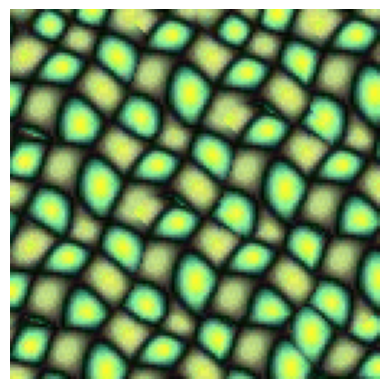

In [99]:
#Alien texture gen
patchSize = (48,48)
overlapSize = (16,16)
GenerateTextureFrom("Data/text0.png", patchSize, overlapSize, "Data/Generated/alien.png", 2000)

/tmp/ipykernel_18565/735969297.py:58: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


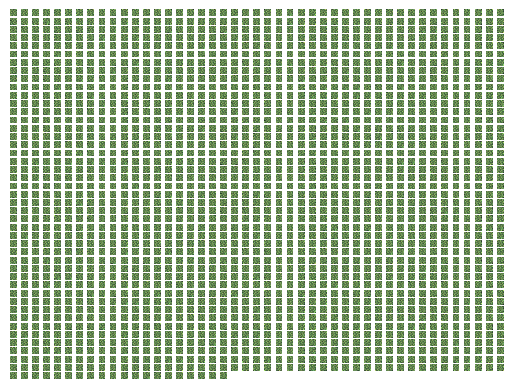

In [100]:
#Make classification data
GenerateClassificationDataFor("Data/Generated/alien.png", "alien")

# 2 : Sand
Observations : 
- resultat correct car src stochastique
- besoin d'un overlap plus petit que les autres pour de meilleur resultat 
- pas besoin de grande taille de patch
    
-> hypothese : plus la source est stochastique plus l'overlap doit etre petit et moins besoin de patch grand

![Exemple](Data/text1.png)

src shape : (99, 108, 3)


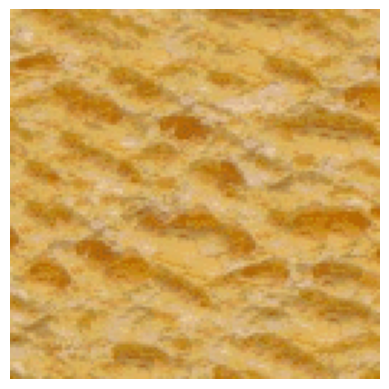

In [101]:
patchSize = (16,16)
overlapSize = (4,4)
GenerateTextureFrom("Data/text1.png", patchSize, overlapSize, "Data/Generated/sand.png")

/tmp/ipykernel_18565/735969297.py:58: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


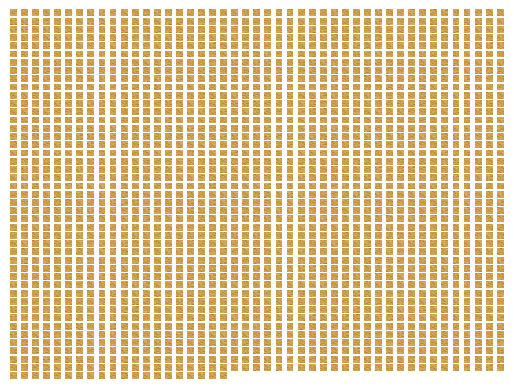

In [102]:
#Make classification data
GenerateClassificationDataFor("Data/Generated/sand.png", "sand")

# 3 : Brick
Observations : 
- nécessite un overlap grand et un patch aussi 

![Exemple](Data/text2.png)

src shape : (77, 107, 3)


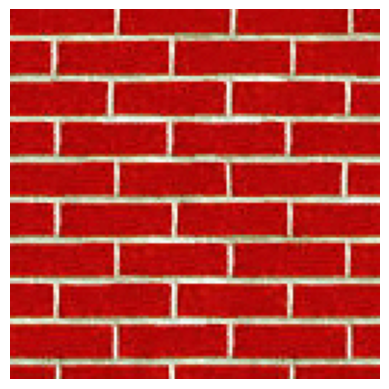

In [103]:
patchSize = (32,32)
overlapSize = (24,24)
GenerateTextureFrom("Data/text2.png", patchSize, overlapSize, "Data/Generated/brick.png")

/tmp/ipykernel_18565/735969297.py:58: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


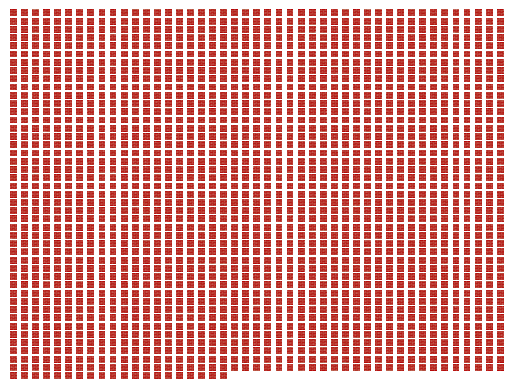

In [104]:
#Make classification data
GenerateClassificationDataFor("Data/Generated/brick.png", "brick")

# 4 : Grill
Observations : 
- Taille de patch pas trop petite
- Overlap pas trop grand

![Exemple](Data/text3.png)

src shape : (65, 68, 3)


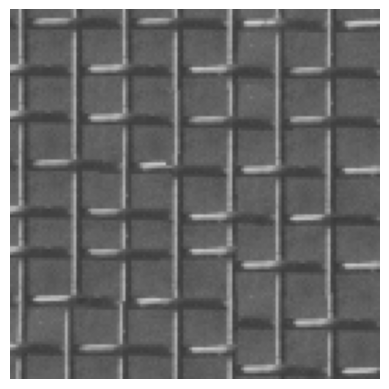

In [105]:
patchSize = (32,32)
overlapSize = (8,8)
GenerateTextureFrom("Data/text3.png", patchSize, overlapSize, "Data/Generated/grill.png")

/tmp/ipykernel_18565/735969297.py:58: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


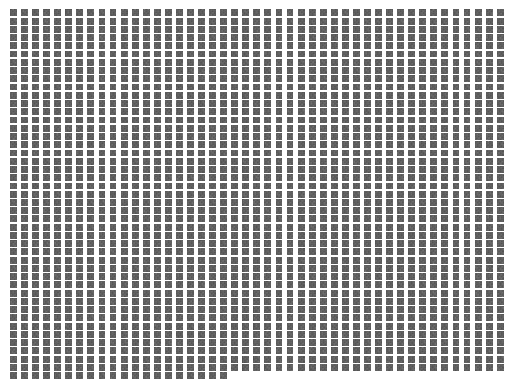

In [106]:
#Make classification data
GenerateClassificationDataFor("Data/Generated/grill.png", "grill")

# 5 : Apples
- Grand patch 
- Grand overlap

![Exemple](Data/text4.png)

src shape : (124, 124, 3)


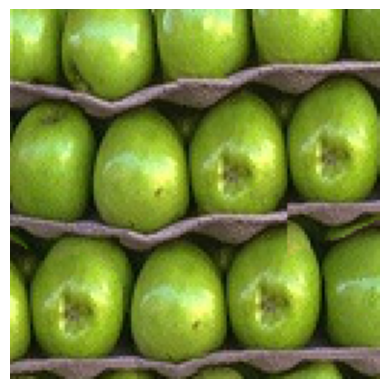

In [107]:
patchSize = (64,64)
overlapSize = (32,32)
GenerateTextureFrom("Data/text4.png", patchSize, overlapSize, "Data/Generated/apples.png")

/tmp/ipykernel_18565/735969297.py:58: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


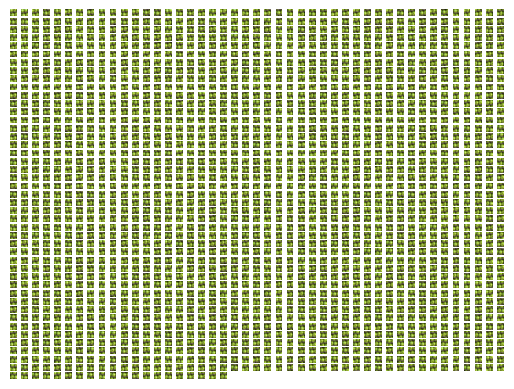

In [108]:
#Make classification data
GenerateClassificationDataFor("Data/Generated/apples.png", "apples")

# 6 : Wicker
- Pas besoin d'une grande taille de patch 
- Overlap moyen

![Exemple](Data/text5.png)

src shape : (128, 128, 3)


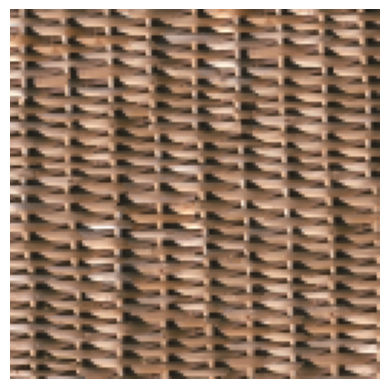

In [109]:
patchSize = (32,32)
overlapSize = (16,16)
GenerateTextureFrom("Data/text5.png", patchSize, overlapSize, "Data/Generated/wicker.png")

/tmp/ipykernel_18565/735969297.py:58: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


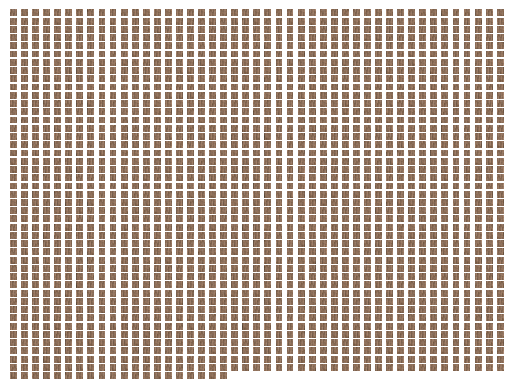

In [110]:
#Make classification data
GenerateClassificationDataFor("Data/Generated/wicker.png", "wicker")

# 7 : Rock 
Observations : 
- très stochastique 
- memes observations que le sable

![Exemple](Data/text6.png)

src shape : (79, 81, 3)


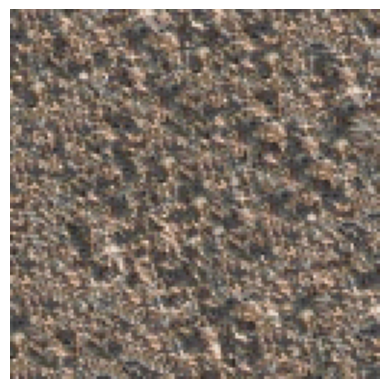

In [111]:
patchSize = (16,16)
overlapSize = (4,4)
GenerateTextureFrom("Data/text6.png", patchSize, overlapSize, "Data/Generated/rock.png")

/tmp/ipykernel_18565/735969297.py:58: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


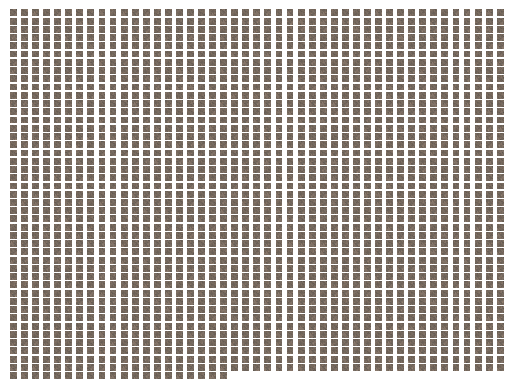

In [112]:
#Make classification data
GenerateClassificationDataFor("Data/Generated/rock.png", "rock")

# 8 : Red Fruits
Observations : 
- Mêmes observations que la pomme

![Exemple](Data/text7.png)

src shape : (92, 92, 3)


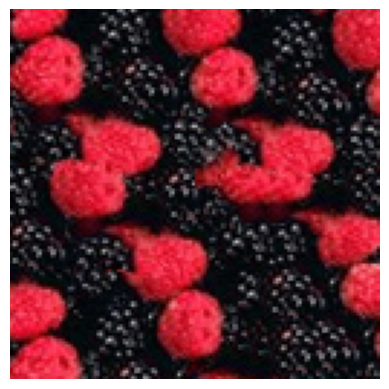

In [113]:
patchSize = (32,32)
overlapSize = (16,16)
GenerateTextureFrom("Data/text7.png", patchSize, overlapSize, "Data/Generated/red_fruits.png")

/tmp/ipykernel_18565/735969297.py:58: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


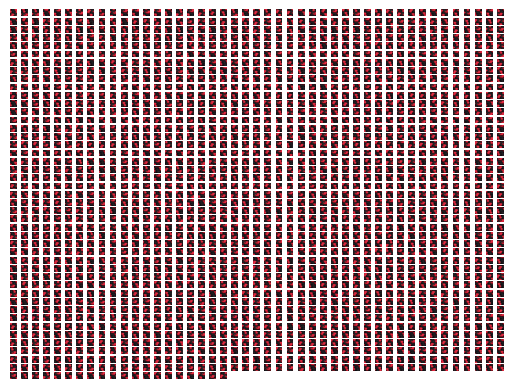

In [114]:
#Make classification data
GenerateClassificationDataFor("Data/Generated/red_fruits.png", "red_fruits")